In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

zip_path = "/content/drive/MyDrive/archive (1).zip"

if os.path.exists(zip_path):
    print("✅ ZIP file found!")
    print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")
else:
    print("❌ ZIP file not found. Searching My Drive...")
    for root, dirs, files in os.walk("/content/drive/MyDrive"):
        if "archive (1).zip" in files:
            print("Found at:", os.path.join(root, "archive (1).zip"))

✅ ZIP file found!
File size: 1.52 GB


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/archive (1).zip"
extract_path = "/content/kidney_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Extraction completed!")
print("Dataset location:", extract_path)


✅ Extraction completed!
Dataset location: /content/kidney_dataset


In [5]:
import os

dataset_path = "/content/kidney_dataset"

for root, dirs, files in os.walk(dataset_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if image_files:
        print(f"{root} --> {len(image_files)} images")

/content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst --> 3709 images
/content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Tumor --> 2283 images
/content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone --> 1377 images
/content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal --> 5077 images


In [6]:
import os

dataset_path = "/content/kidney_dataset"

for root, dirs, files in os.walk(dataset_path):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if images:
        print(os.path.relpath(root, dataset_path), ":", len(images), "images")

CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst : 3709 images
CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Tumor : 2283 images
CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone : 1377 images
CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal : 5077 images


In [7]:
import os
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

dataset_path = (
    "/content/kidney_dataset/"
    "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/"
    "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
)

classes = ["Cyst", "Normal", "Stone", "Tumour"]

for class_name in classes:
    folder = os.path.join(dataset_path, class_name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]
    print(f"{class_name}: {len(images)} images")

Cyst: 3709 images
Normal: 5077 images
Stone: 1377 images


FileNotFoundError: [Errno 2] No such file or directory: '/content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Tumour'

In [8]:
import os

dataset_path = (
    "/content/kidney_dataset/"
    "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/"
    "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
)

classes = ["Cyst", "Normal", "Stone", "Tumor"]

for class_name in classes:
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"{class_name}: {len(images)} images")

Cyst: 3709 images
Normal: 5077 images
Stone: 1377 images
Tumor: 2283 images


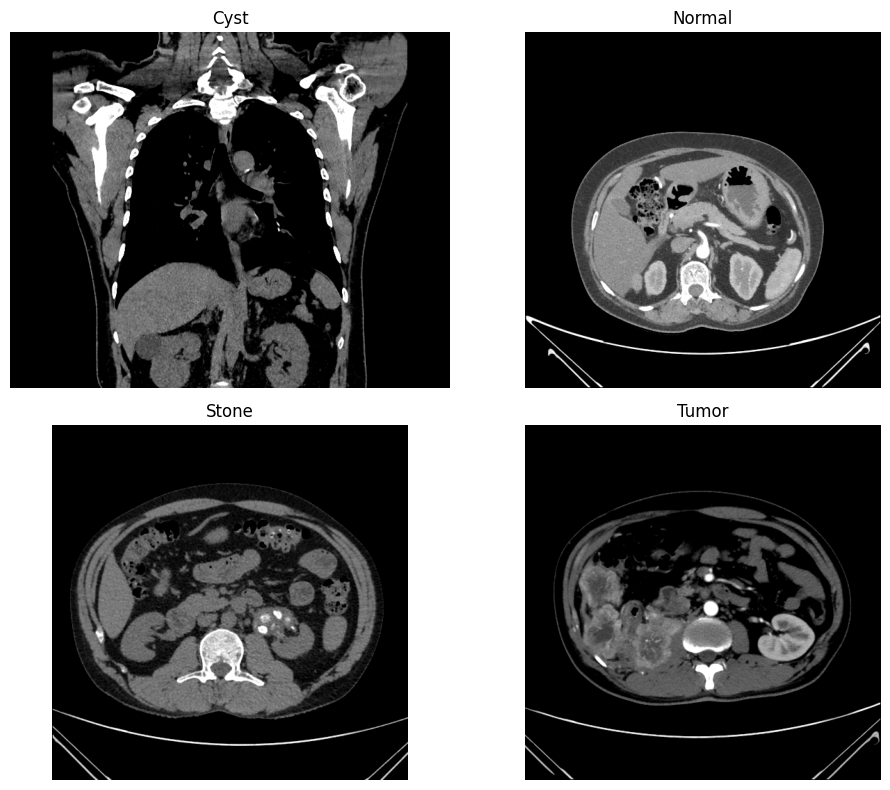

In [9]:
import matplotlib.pyplot as plt
import os
from tensorflow.keras.utils import load_img

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, class_name)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    img = load_img(os.path.join(folder, images[0]))

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import os

for class_name in classes:
    folder = os.path.join(dataset_path, class_name)
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"\n{class_name} — example filenames:")
    for name in files[:5]:
        print(" ", name)


Cyst — example filenames:
  Cyst- (1555).jpg
  Cyst- (22).jpg
  Cyst- (885).jpg
  Cyst- (1781).jpg
  Cyst- (3238).jpg

Normal — example filenames:
  Normal- (3757).jpg
  Normal- (4270).jpg
  Normal- (56).jpg
  Normal- (661).jpg
  Normal- (2758).jpg

Stone — example filenames:
  Stone- (1060).jpg
  Stone- (840).jpg
  Stone- (54).jpg
  Stone- (665).jpg
  Stone- (516).jpg

Tumor — example filenames:
  Tumor- (1391).jpg
  Tumor- (1067).jpg
  Tumor- (520).jpg
  Tumor- (1330).jpg
  Tumor- (1131).jpg


In [11]:
import os
import numpy as np
from sklearn.model_selection import train_test_split

classes = ["Cyst", "Normal", "Stone", "Tumor"]
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

file_paths = []
labels = []

for label, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, class_name)

    for filename in os.listdir(folder):
        if filename.lower().endswith(image_extensions):
            file_paths.append(os.path.join(folder, filename))
            labels.append(label)

file_paths = np.array(file_paths)
labels = np.array(labels)

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Split the remaining 30% equally: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("\nClass order:", classes)

Training images: 8712
Validation images: 1867
Test images: 1867

Class order: ['Cyst', 'Normal', 'Stone', 'Tumor']


In [12]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

# 1. Load and preprocess CT images
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)
train_ds = (
    train_ds.shuffle(3000, seed=42)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = (
    val_ds.map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = (
    test_ds.map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# 2. Create the pretrained CNN
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Give extra weight to minority classes
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(weights))

print("Class weights:", class_weights)
model.summary()

# 4. Train the model
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=callbacks
)

print("Training completed!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Class weights: {0: np.float64(0.8389830508474576), 1: np.float64(0.6128306133933596), 2: np.float64(2.259336099585062), 3: np.float64(1.362953692115144)}


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 63s 184ms/step - accuracy: 0.6671 - loss: 0.8246 - val_accuracy: 0.8827 - val_loss: 0.3884 - learning_rate: 0.0010
Epoch 2/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 27s 99ms/step - accuracy: 0.8413 - loss: 0.4512 - val_accuracy: 0.8939 - val_loss: 0.3209 - learning_rate: 0.0010
Epoch 3/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 28s 101ms/step - accuracy: 0.8796 - loss: 0.3494 - val_accuracy: 0.9223 - val_loss: 0.2553 - learning_rate: 0.0010
Epoch 4/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 96ms/step - accuracy: 0.9022 - loss: 0.2897 - val_accuracy: 0.9475 - val_loss: 0.2052 - learning_rate: 0.0010
Epoch 5/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9138 - loss: 0.2629 - val_accuracy: 0.9657 - val_loss: 0.1554 - learning_rate: 0.0010
Training completed!


59/59 ━━━━━━━━━━━━━━━━━━━━ 15s 142ms/step
TEST ACCURACY: 95.66 %

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

        Cyst       0.98      0.96      0.97       557
      Normal       0.99      0.96      0.97       761
       Stone       0.88      0.92      0.90       207
       Tumor       0.91      0.96      0.93       342

    accuracy                           0.96      1867
   macro avg       0.94      0.95      0.94      1867
weighted avg       0.96      0.96      0.96      1867



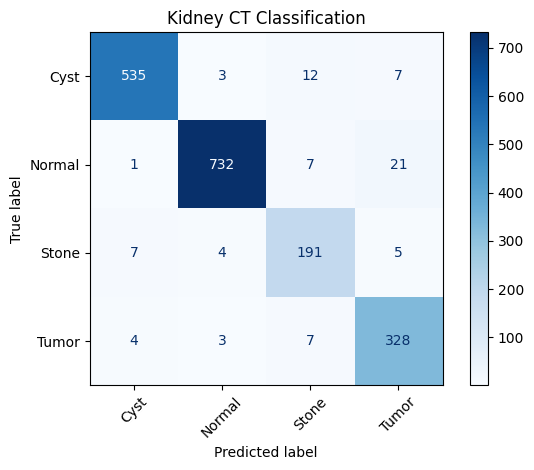


STONE RECALL: 92.27%


In [14]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import numpy as np
import matplotlib.pyplot as plt

# Predict on the held-out test dataset
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("TEST ACCURACY:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=list(range(len(classes)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Kidney CT Classification")
plt.tight_layout()
plt.show()

# Stone recall
stone_index = classes.index("Stone")
stone_recall = cm[stone_index, stone_index] / cm[stone_index].sum()

print(f"\nSTONE RECALL: {stone_recall * 100:.2f}%")

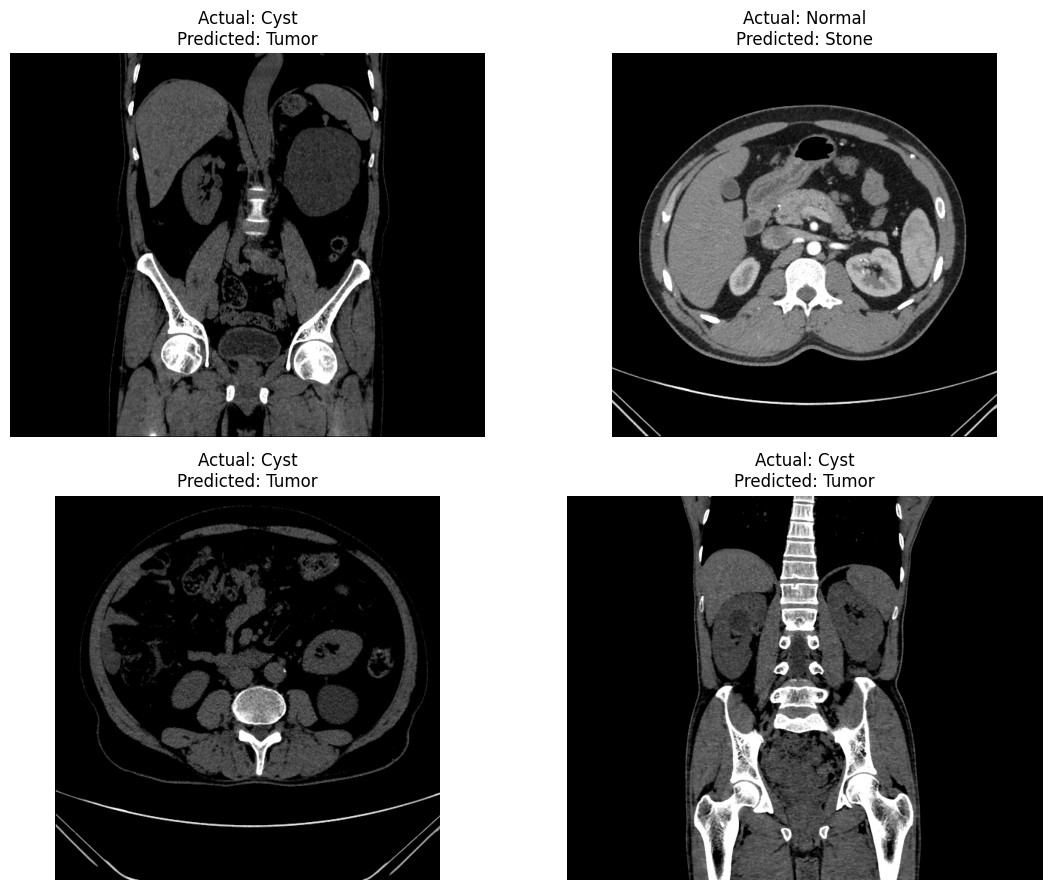

Total misclassified images: 81


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

wrong = np.where(y_pred != y_test)[0]
n = min(4, len(wrong))

plt.figure(figsize=(12, 9))

for i, idx in enumerate(wrong[:n]):
    img = load_img(X_test[idx])

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(
        f"Actual: {classes[y_test[idx]]}\n"
        f"Predicted: {classes[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Total misclassified images:", len(wrong))

In [16]:
import os

save_dir = "/content/drive/MyDrive/Kidney_CNN_Project"
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, "kidney_mobilenetv2.keras"))

print("Model saved successfully!")

Model saved successfully!
